In [1]:
import os,torch
import numpy as np, pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from torch.optim import Adam


In [2]:

df=pd.read_csv("../machine-predictive/predictive_maintenance.csv")
display(df.head()); df.info()
print(df.isna().sum())
print(df.duplicated().sum())
print(df["Failure Type"].value_counts())
print(pd.crosstab(df["Target"], df["Failure Type"]))


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  str    
dtypes: float64(3), int64(4), str(3)
memory usage: 781.4 KB
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]          

In [3]:
df = df[~((df["Target"] == 1)&(df["Failure Type"]=="No Failure"))]
df = df.drop(columns=["UDI","Product ID","Target"])
df["Type"] =df["Type"].map({"L":0,"M": 1,"H":2})
print(df.shape, df["Type"].isna().sum())
print(df["Failure Type"].value_counts())

(9991, 7) 0
Failure Type
No Failure                  9643
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64


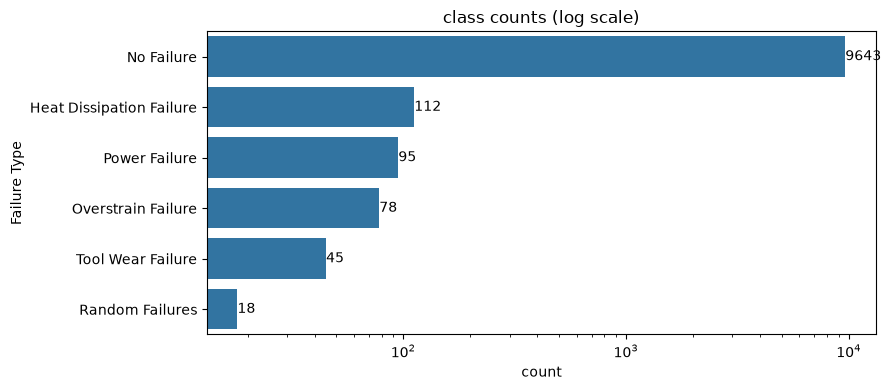

In [5]:
order=df["Failure Type"].value_counts().index
plt.figure(figsize=(9, 4))
ax =sns.countplot(data=df,y="Failure Type",order=order)
ax.bar_label(ax.containers[0])
ax.set_xscale("log")
plt.title("class counts (log scale)")
plt.tight_layout()
plt.savefig("figures/class_counts.png", dpi=150,bbox_inches="tight")
plt.show()

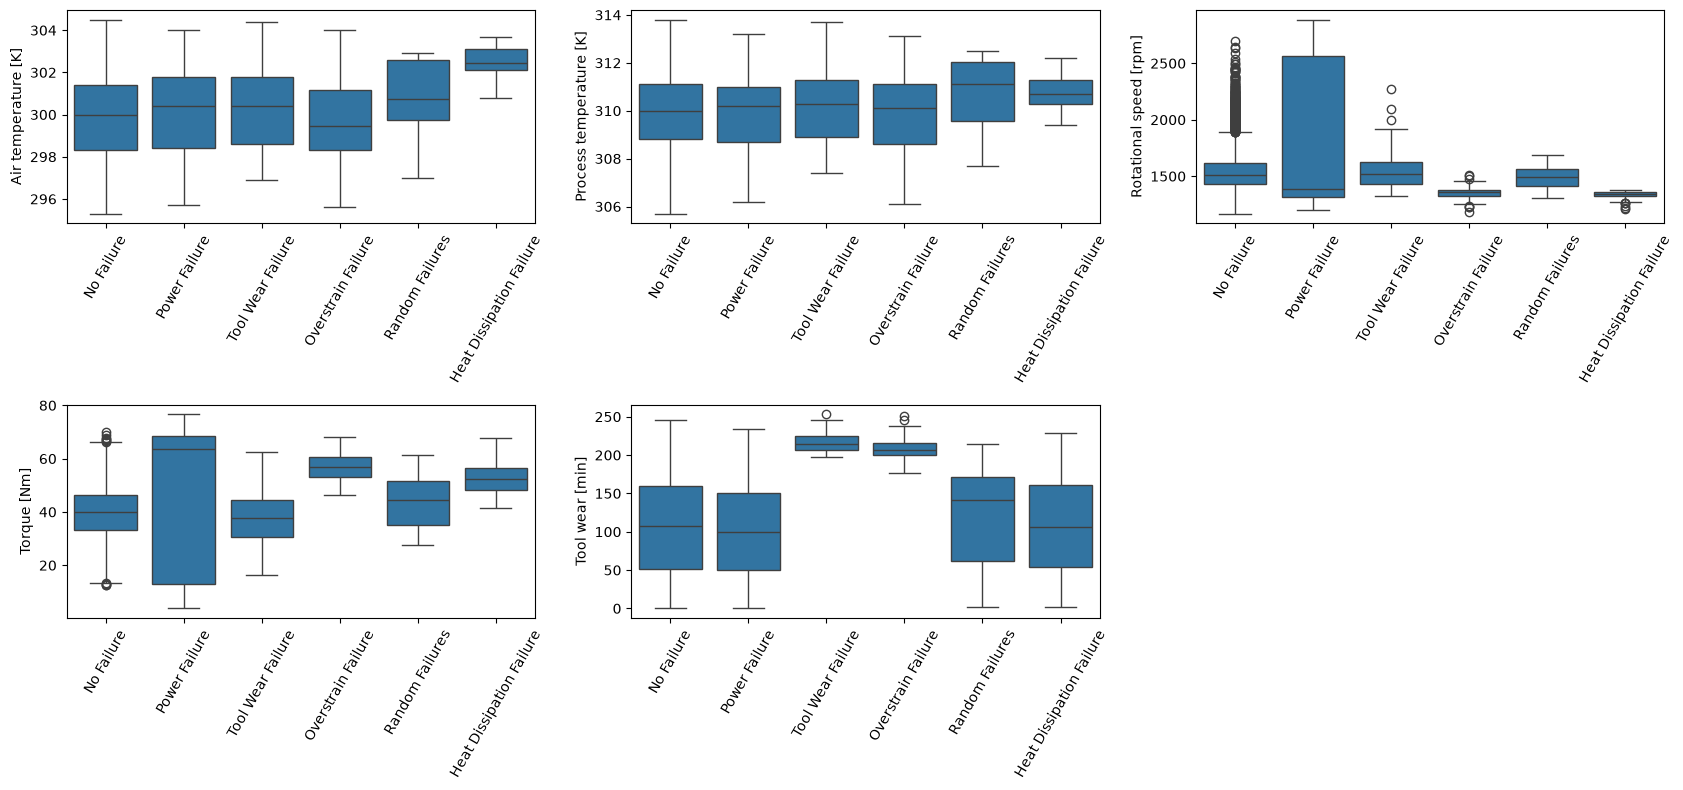

In [6]:
num = ["Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]"]
fig,ax= plt.subplots(2,3,figsize=(17, 8))
for a,c in zip(ax.flat, num):
    sns.boxplot(data=df, x="Failure Type", y=c, ax=a)
    a.set_xlabel("")
    a.tick_params(axis="x", rotation=60)
ax.flat[-1].axis("off")
plt.tight_layout()
plt.savefig("figures/features_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

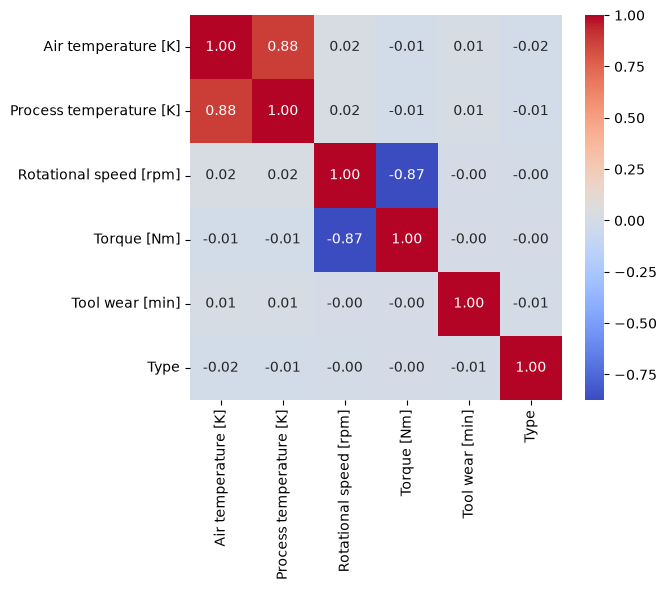

In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[num + ["Type"]].corr(),annot=True,fmt=".2f", cmap="coolwarm")
plt.savefig("figures/corr_part2.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# encode the labels
le = LabelEncoder()
y = le.fit_transform(df["Failure Type"])
print(le.classes_)
X = df.drop(columns=["Failure Type"])


['Heat Dissipation Failure' 'No Failure' 'Overstrain Failure'
 'Power Failure' 'Random Failures' 'Tool Wear Failure']


In [9]:
# stratified split: keeps the class proportions in train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)
print(np.bincount(y_train), np.bincount(y_test))

(7992, 6) (1999, 6)
[  90 7714   62   76   14   36] [  22 1929   16   19    4    9]


In [10]:
# standardize the numeric columns (fit on the training set only)
sc = StandardScaler()
X_train[num] = sc.fit_transform(X_train[num])
X_test[num] = sc.transform(X_test[num])
print(X_train[num].mean().round(2).values, X_test[num].mean().round(2).values)

[-0.  0.  0.  0. -0.] [-0.    0.   -0.04  0.03  0.03]


In [11]:
#Balance - augmentation technique
from imblearn.over_sampling import SMOTENC

# the 5 failure classes are brought up to 1000 samples each, No Failure (class 1) stays as it is
strategy = {0: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000}
sm = SMOTENC(categorical_features=[0], sampling_strategy=strategy, random_state=42)
X_train_bal, y_train_bal = sm.fit_resample(X_train, y_train)
print(X_train_bal.shape)
print(np.bincount(y_train_bal))
print(X_train_bal["Type"].unique())

(12714, 6)
[1000 7714 1000 1000 1000 1000]
[0 1 2]


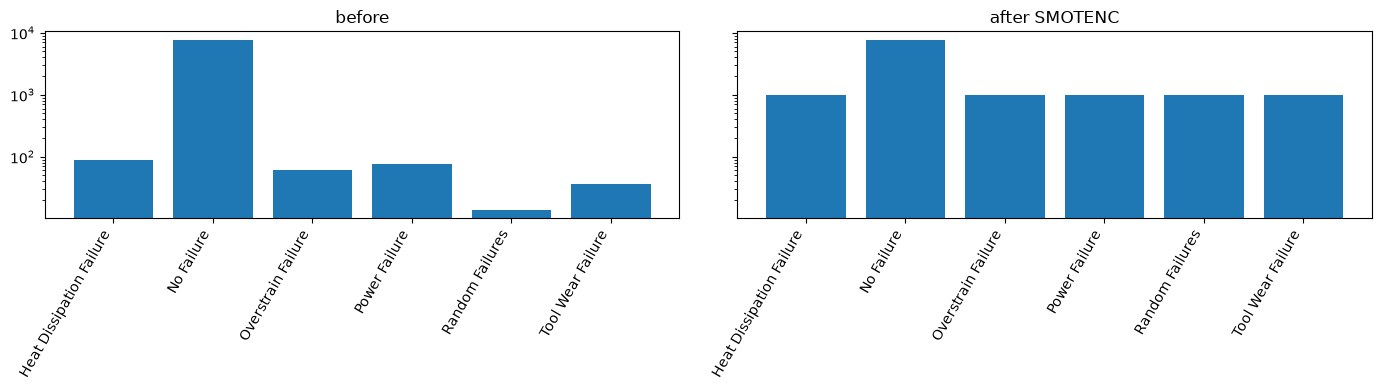

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for a, c, t in zip(ax, [np.bincount(y_train), np.bincount(y_train_bal)], ["before", "after SMOTENC"]):
    a.bar(range(6), c)
    a.set_yscale("log")
    a.set_xticks(range(6))
    a.set_xticklabels(le.classes_, rotation=60, ha="right")
    a.set_title(t)
plt.tight_layout()
plt.savefig("figures/balancing.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
from torch.utils.data import Dataset, DataLoader
from torch.nn import (
    Linear, ReLU, Dropout, BatchNorm1d,
    Identity, Module, CrossEntropyLoss,)
from torch.nn.init import kaiming_uniform_, xavier_uniform_
from torch.optim import SGD
from sklearn.metrics import accuracy_score, f1_score
from tqdm import tqdm

In [21]:
# dataset definition
class MaintenanceDataset(Dataset):
    #load dataset
    def __init__(self, X, y):
        #store the inputs and outputs
        self.X = np.asarray(X).astype('float32')
        self.y = np.asarray(y).astype('int64')
    # number of rows in the dataset
    def __len__(self):
        return len(self.X)
    #get a row at an index
    def __getitem__(self, idx):
        return [self.X[idx], self.y[idx]]

In [22]:
# prepare the dataset
def prepare_data(X_train_bal, y_train_bal, X_train, y_train, X_test, y_test):
    # prepare data loaders
    train_dl = DataLoader(MaintenanceDataset(X_train_bal, y_train_bal), batch_size=32, shuffle=True)
    train_orig_dl = DataLoader(MaintenanceDataset(X_train, y_train), batch_size=1024, shuffle=False)
    test_dl = DataLoader(MaintenanceDataset(X_test, y_test), batch_size=1024, shuffle=False)
    return train_dl, train_orig_dl, test_dl

train_dl, train_orig_dl, test_dl = prepare_data(X_train_bal, y_train_bal, X_train, y_train, X_test, y_test)
print(len(train_dl.dataset), len(train_orig_dl.dataset), len(test_dl.dataset))

12714 7992 1999


In [23]:
# model definition
class MLP(Module):
    # define model elements
    def __init__(self, n_inputs, n_classes, n_hidden1=64, n_hidden2=32, p_drop=0.0, use_bn=False):
        super(MLP, self).__init__()
        # input to first hidden layer
        self.hidden1 = Linear(n_inputs, n_hidden1)
        kaiming_uniform_(self.hidden1.weight, nonlinearity='relu')
        self.bn1 = BatchNorm1d(n_hidden1) if use_bn else Identity()
        self.act1 = ReLU()
        self.drop1 = Dropout(p_drop)
        # second hidden layer
        self.hidden2 = Linear(n_hidden1, n_hidden2)
        kaiming_uniform_(self.hidden2.weight, nonlinearity='relu')
        self.bn2 = BatchNorm1d(n_hidden2) if use_bn else Identity()
        self.act2 = ReLU()
        self.drop2 = Dropout(p_drop)
        # output layer
        self.hidden3 = Linear(n_hidden2, n_classes)
        xavier_uniform_(self.hidden3.weight)

    # forward propagate input
    def forward(self, X):
        # input to first hidden layer
        X = self.hidden1(X)
        X = self.bn1(X)
        X = self.act1(X)
        X = self.drop1(X)
        # second hidden layer
        X = self.hidden2(X)
        X = self.bn2(X)
        X = self.act2(X)
        X = self.drop2(X)
        # output layer(raw scores)
        X = self.hidden3(X)
        return X

In [25]:
# evaluate the model
def evaluate_model(dl, model):
    model.eval()
    criterion = CrossEntropyLoss()
    predictions, actuals = list(), list()
    total = 0.0
    with torch.no_grad():
        for i, (inputs, targets) in enumerate(dl):
            yhat = model(inputs)
            total += criterion(yhat, targets).item() * len(targets)
            # convert to class labels
            predictions.append(yhat.argmax(dim=1).numpy())
            actuals.append(targets.numpy())
    predictions, actuals = np.concatenate(predictions), np.concatenate(actuals)
    loss = total / len(actuals)
    acc = accuracy_score(actuals, predictions)
    f1 = f1_score(actuals, predictions, average='macro')
    return loss, acc, f1

In [28]:
# train the model
def train_model(train_dl, test_dl, model, epochs=50, lr=0.01, optimizer_class=SGD, weight_decay=0.0):
    # define the optimization
    criterion = CrossEntropyLoss()
    if optimizer_class == SGD:
        optimizer = SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    else:
        optimizer = optimizer_class(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': [], 'test_f1': []}
    # enumerate epochs
    for epoch in tqdm(range(epochs), desc='Training Epochs'):
        model.train()
        # enumerate mini batches
        for batch, (inputs, targets) in enumerate(train_dl):
            # clear the gradients
            optimizer.zero_grad()
            # compute the model output
            yhat = model(inputs)
            # calculate loss
            loss = criterion(yhat, targets)
            # credit assignment
            loss.backward()
            # update model weights
            optimizer.step()
        # evaluate on the train and test sets after each epoch
        train_loss, train_acc, _ = evaluate_model(train_dl, model)
        test_loss, test_acc, test_f1 = evaluate_model(test_dl, model)
        history['train_loss'].append(train_loss)
        history['test_loss'].append(test_loss)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)
        history['test_f1'].append(test_f1)
        print('Epoch %03d | Train loss: %.4f, acc: %.3f | Test loss: %.4f, acc: %.3f, macro F1: %.3f'
              % (epoch+1, train_loss, train_acc, test_loss, test_acc, test_f1))
    return history

In [29]:

def plot_history(history, name):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(history['train_loss'], label='train')
    ax[0].plot(history['test_loss'], label='test')
    ax[0].set(title='Loss / Epochs', xlabel='epoch', ylabel='cross-entropy')
    ax[0].legend()
    ax[1].plot(history['train_acc'], label='train')
    ax[1].plot(history['test_acc'], label='test')
    ax[1].set(title='Accuracy / Epochs', xlabel='epoch', ylabel='accuracy')
    ax[1].legend()
    plt.tight_layout()
    plt.savefig("figures/%s_curves.png" % name, dpi=150, bbox_inches="tight")
    plt.show()

MLP(
  (hidden1): Linear(in_features=6, out_features=64, bias=True)
  (bn1): Identity()
  (act1): ReLU()
  (drop1): Dropout(p=0.0, inplace=False)
  (hidden2): Linear(in_features=64, out_features=32, bias=True)
  (bn2): Identity()
  (act2): ReLU()
  (drop2): Dropout(p=0.0, inplace=False)
  (hidden3): Linear(in_features=32, out_features=6, bias=True)
)
2726


Training Epochs:   0%|                                                                        | 0/50 [00:00<?, ?it/s]/home/vernical/Desktop/MST-SIBD/S3/deep-learning/assignment-1/DeepLearning-Lab1/.venv/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12040). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
Training Epochs:   2%|█▎                                                              | 1/50 [00:00<00:27,  1.79it/s]

Epoch 001 | Train loss: 0.3364, acc: 0.867 | Test loss: 0.2909, acc: 0.894, macro F1: 0.409


Training Epochs:   4%|██▌                                                             | 2/50 [00:01<00:26,  1.80it/s]

Epoch 002 | Train loss: 0.2612, acc: 0.902 | Test loss: 0.2743, acc: 0.895, macro F1: 0.472


...

Epoch 048 | Train loss: 0.0558, acc: 0.982 | Test loss: 0.2521, acc: 0.950, macro F1: 0.513


Training Epochs:  98%|█████████████████████████████████████████████████████████████▋ | 49/50 [00:16<00:00,  1.81it/s]

Epoch 049 | Train loss: 0.0595, acc: 0.979 | Test loss: 0.2590, acc: 0.954, macro F1: 0.533


Training Epochs: 100%|███████████████████████████████████████████████████████████████| 50/50 [00:17<00:00,  2.94it/s]

Epoch 050 | Train loss: 0.0533, acc: 0.982 | Test loss: 0.2506, acc: 0.958, macro F1: 0.542


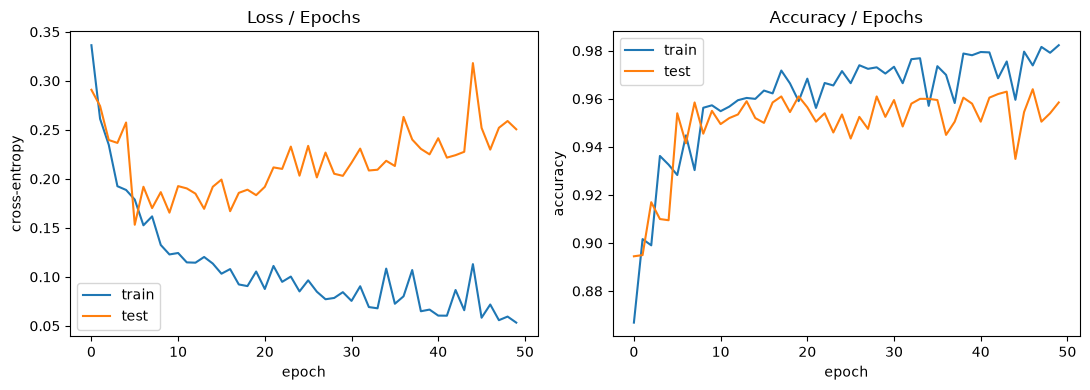

In [30]:
model = MLP(n_inputs=6, n_classes=6)
print(model)
print(sum(p.numel() for p in model.parameters()))
history_base = train_model(train_dl, test_dl, model, epochs=50, lr=0.01, optimizer_class=SGD)
plot_history(history_base, "baseline_initial")

In [31]:
# 5. GridSearch from sklearn library to choose best hyperparameters
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import GridSearchCV

class PyTorchMLPClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, n_inputs=6, n_classes=6, n_hidden1=64, n_hidden2=32,
                 lr=0.01, optimizer_class=Adam, epochs=30, batch_size=64,
                 p_drop=0.0, use_bn=False, weight_decay=0.0):
        self.n_inputs = n_inputs
        self.n_classes = n_classes
        self.n_hidden1 = n_hidden1
        self.n_hidden2 = n_hidden2
        self.lr = lr
        self.optimizer_class = optimizer_class
        self.epochs = epochs
        self.batch_size = batch_size
        self.p_drop = p_drop
        self.use_bn = use_bn
        self.weight_decay = weight_decay

    def fit(self, X, y):
        torch.manual_seed(42)
        self.classes_ = np.unique(y)
        self.model_ = MLP(
            self.n_inputs, self.n_classes,
            n_hidden1=self.n_hidden1, n_hidden2=self.n_hidden2,
            p_drop=self.p_drop, use_bn=self.use_bn
        )
        criterion = CrossEntropyLoss()
        if self.optimizer_class == SGD:
            optimizer = SGD(self.model_.parameters(), lr=self.lr, momentum=0.9, weight_decay=self.weight_decay)
        else:
            optimizer = self.optimizer_class(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)

        ds = MaintenanceDataset(X, y)
        dl = DataLoader(ds, batch_size=self.batch_size, shuffle=True)

        self.model_.train()
        for _ in range(self.epochs):
            for inputs, targets in dl:
                optimizer.zero_grad()
                out = self.model_(inputs)
                loss = criterion(out, targets)
                loss.backward()
                optimizer.step()
        return self

    def predict(self, X):
        self.model_.eval()
        X_tensor = torch.tensor(np.asarray(X, dtype='float32'))
        with torch.no_grad():
            logits = self.model_(X_tensor)
            return logits.argmax(dim=1).numpy()


Fitting 3 folds for each of 32 candidates, totalling 96 fits
Best Hyperparameters: {'epochs': 50, 'lr': 0.001, 'n_hidden1': 128, 'n_hidden2': 64, 'optimizer_class': <class 'torch.optim.adam.Adam'>}
Best CV Macro F1: 0.6311


In [33]:

param_grid = {
    'n_hidden1': [64, 128],
    'n_hidden2': [32, 64],
    'lr': [0.01, 0.001],
    'optimizer_class': [SGD, Adam],
    'epochs': [30, 50]
}

grid = GridSearchCV( estimator=PyTorchMLPClassifier(), param_grid=param_grid,scoring='f1_macro',cv=3,n_jobs=1,verbose=1)
grid.fit(X_train_bal, y_train_bal)

print("Best Hyperparameters:", grid.best_params_)
print("Best CV Macro F1:", round(grid.best_score_, 4))

Fitting 3 folds for each of 32 candidates, totalling 96 fits
Best Hyperparameters: {'epochs': 50, 'lr': 0.001, 'n_hidden1': 128, 'n_hidden2': 64, 'optimizer_class': <class 'torch.optim.adam.Adam'>}
Best CV Macro F1: 0.6311


Training Epochs:   2%|█▎                                                              | 1/50 [00:00<00:34,  1.40it/s]

Epoch 001 | Train loss: 0.3245, acc: 0.870 | Test loss: 0.2680, acc: 0.909, macro F1: 0.431


Training Epochs:   4%|██▌                                                             | 2/50 [00:01<00:34,  1.38it/s]

Epoch 002 | Train loss: 0.2485, acc: 0.896 | Test loss: 0.1947, acc: 0.943, macro F1: 0.472


Training Epochs:   6%|███▊                                                            | 3/50 [00:02<00:34,  1.37it/s]

...

Epoch 048 | Train loss: 0.0406, acc: 0.988 | Test loss: 0.2622, acc: 0.961, macro F1: 0.544


Training Epochs:  98%|█████████████████████████████████████████████████████████████▋ | 49/50 [00:35<00:00,  1.30it/s]

Epoch 049 | Train loss: 0.0401, acc: 0.989 | Test loss: 0.2676, acc: 0.967, macro F1: 0.544


Training Epochs: 100%|███████████████████████████████████████████████████████████████| 50/50 [00:35<00:00,  1.40it/s]

Epoch 050 | Train loss: 0.0448, acc: 0.984 | Test loss: 0.2884, acc: 0.954, macro F1: 0.546


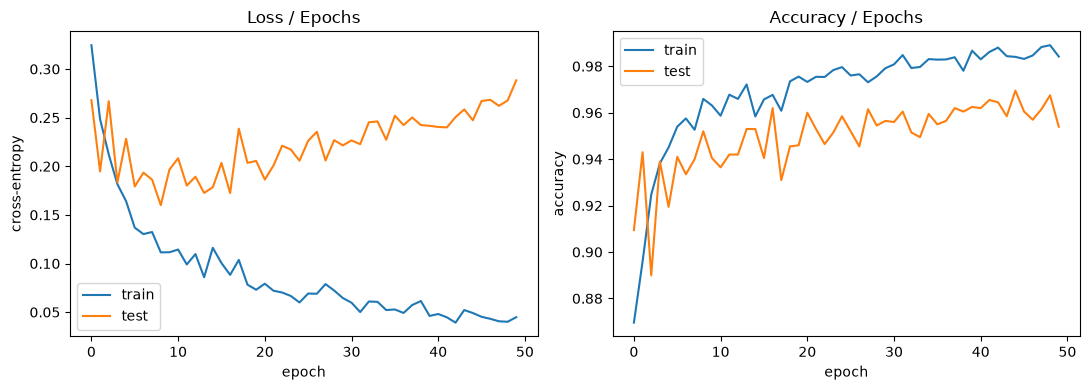

In [34]:
# 6. Train the best model from GridSearch and visualize (Loss/Epochs) and (Accuracy/Epochs)
best_params = grid.best_params_


best_model = MLP(
    n_inputs=6, n_classes=6,
    n_hidden1=best_params['n_hidden1'],
    n_hidden2=best_params['n_hidden2'],
    p_drop=0.0,
    use_bn=False)

history_best = train_model(
    train_dl, test_dl, best_model,
    epochs=best_params['epochs'],
    lr=best_params['lr'],
    optimizer_class=best_params['optimizer_class'],
    weight_decay=0.0)

plot_history(history_best, "gridsearch_best")

In [35]:
# 7. Calculate accuracy, sensitivity (recall), precision, and F1 score on both training and test datasets
from sklearn.metrics import classification_report, precision_score, recall_score, confusion_matrix

def compute_detailed_metrics(dl, model, split_name, class_names):
    model.eval()
    preds, actuals = [], []
    with torch.no_grad():
        for inputs, targets in dl:
            logits = model(inputs)
            preds.append(logits.argmax(dim=1).numpy())
            actuals.append(targets.numpy())
    y_pred = np.concatenate(preds)
    y_true = np.concatenate(actuals)

    acc = accuracy_score(y_true, y_pred)
    sens_macro = recall_score(y_true, y_pred, average='macro', zero_division=0)
    sens_weighted = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    prec_macro = precision_score(y_true, y_pred, average='macro', zero_division=0)
    prec_weighted = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    f1_mac = f1_score(y_true, y_pred, average='macro', zero_division=0)
    f1_w = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    print(f"================ {split_name} ================")
    print(f"Accuracy               : {acc:.4f}")
    print(f"Sensitivity (Macro)    : {sens_macro:.4f} | (Weighted): {sens_weighted:.4f}")
    print(f"Precision   (Macro)    : {prec_macro:.4f} | (Weighted): {prec_weighted:.4f}")
    print(f"F1 Score    (Macro)    : {f1_mac:.4f} | (Weighted): {f1_w:.4f}\n")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))
    return {'acc': acc, 'sens_macro': sens_macro, 'prec_macro': prec_macro, 'f1_macro': f1_mac, 'f1_weighted': f1_w}

metrics_train_bal = compute_detailed_metrics(train_dl, best_model, "Train Set (SMOTENC Balanced)", le.classes_)
metrics_train_orig = compute_detailed_metrics(train_orig_dl, best_model, "Train Set (Original Unbalanced)", le.classes_)
metrics_test_base = compute_detailed_metrics(test_dl, best_model, "Test Set (Unregularized Best)", le.classes_)

================ Train Set (SMOTENC Balanced) ================
Accuracy               : 0.9842
Sensitivity (Macro)    : 0.9910 | (Weighted): 0.9842
Precision   (Macro)    : 0.9717 | (Weighted): 0.9849
F1 Score    (Macro)    : 0.9810 | (Weighted): 0.9843

                          precision    recall  f1-score   support

Heat Dissipation Failure      0.986     0.999     0.993      1000
              No Failure      0.997     0.978     0.987      7714
      Overstrain Failure      0.977     0.997     0.987      1000
           Power Failure      0.989     0.982     0.985      1000
         Random Failures      0.971     0.992     0.981      1000
       Tool Wear Failure      0.911     0.998     0.952      1000

                accuracy                          0.984     12714
               macro avg      0.972     0.991     0.981     12714
            weighted avg      0.985     0.984     0.984     12714

================ Train Set (Original Unbalanced) ================
Accuracy        

In [39]:
# 8. Apply regularization techniques (Dropout, BatchNorm, L2 Weight Decay, Early Stopping) and compare with first model
import copy

def train_model_with_early_stopping(train_dl, test_dl, model, epochs=60, lr=0.01,optimizer_class=Adam, weight_decay=1e-4, patience=10):
    criterion = CrossEntropyLoss()
    if optimizer_class == SGD:
        optimizer = SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    else:
        optimizer = optimizer_class(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': [], 'test_f1': []}
    best_loss = float('inf')
    best_state = copy.deepcopy(model.state_dict())
    wait = 0

    for epoch in tqdm(range(epochs), desc='Regularized Training'):
        model.train()
        for inputs, targets in train_dl:
            optimizer.zero_grad()
            yhat = model(inputs)
            loss = criterion(yhat, targets)
            loss.backward()
            optimizer.step()

        train_loss, train_acc, _ = evaluate_model(train_dl, model)
        test_loss, test_acc, test_f1 = evaluate_model(test_dl, model)
        history['train_loss'].append(train_loss)
        history['test_loss'].append(test_loss)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)
        history['test_f1'].append(test_f1)

        if test_loss < best_loss - 1e-4:
            best_loss = test_loss
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping at epoch {epoch+1} (Best Test Loss: {best_loss:.4f})")
                break

    model.load_state_dict(best_state)
    return history


Regularized Training:  80%|██████████████████████████████████████████████▍           | 48/60 [00:39<00:09,  1.21it/s]

Early stopping at epoch 49 (Best Test Loss: 0.1482)


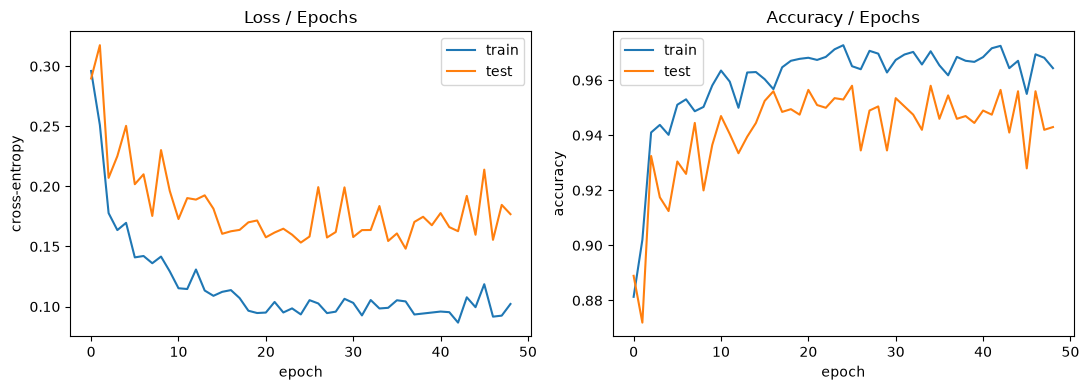

================ Regularized Model - Train Set (Original) ================
Accuracy               : 0.9653
Sensitivity (Macro)    : 0.8734 | (Weighted): 0.9653
Precision   (Macro)    : 0.5892 | (Weighted): 0.9837
F1 Score    (Macro)    : 0.6672 | (Weighted): 0.9728

                          precision    recall  f1-score   support

Heat Dissipation Failure      0.722     0.922     0.810        90
              No Failure      0.997     0.968     0.982      7714
      Overstrain Failure      0.766     0.952     0.849        62
           Power Failure      0.687     0.895     0.777        76
         Random Failures      0.164     0.643     0.261        14
       Tool Wear Failure      0.200     0.861     0.325        36

                accuracy                          0.965      7992
               macro avg      0.589     0.873     0.667      7992
            weighted avg      0.984     0.965     0.973      7992

================ Regularized Model - Test Set ================
Accurac

,Model,Test Accuracy,Test Sensitivity (Macro),Test Precision (Macro),Test F1 (Macro),Test F1 (Weighted)
0,Baseline MLP (No Regularization),0.9540,0.6235,0.4926,0.5461,0.9640
1,Regularized MLP (Dropout 0.2 + BN + L2 + Early...,0.9545,0.5752,0.4780,0.5171,0.9633


In [38]:
reg_model = MLP(
    n_inputs=6, n_classes=6,
    n_hidden1=best_params['n_hidden1'],
    n_hidden2=best_params['n_hidden2'],
    p_drop=0.1,
    use_bn=False
)

history_reg = train_model_with_early_stopping(
    train_dl, test_dl, reg_model,
    epochs=60,
    lr=0.003,
    optimizer_class=Adam,
    weight_decay=5e-4,
    patience=12
)

plot_history(history_reg, "regularized_mlp")

metrics_train_reg = compute_detailed_metrics(train_orig_dl, reg_model, "Regularized Model - Train Set (Original)", le.classes_)
metrics_test_reg = compute_detailed_metrics(test_dl, reg_model, "Regularized Model - Test Set", le.classes_)
comparison_df = pd.DataFrame([
    {
        'Model': 'Baseline MLP (No Regularization)',
        'Test Accuracy': round(metrics_test_base['acc'], 4),
        'Test Sensitivity (Macro)': round(metrics_test_base['sens_macro'], 4),
        'Test Precision (Macro)': round(metrics_test_base['prec_macro'], 4),
        'Test F1 (Macro)': round(metrics_test_base['f1_macro'], 4),
        'Test F1 (Weighted)': round(metrics_test_base['f1_weighted'], 4),
    },
    {
        'Model': 'Regularized MLP (Dropout 0.2 + BN + L2 + EarlyStop)',
        'Test Accuracy': round(metrics_test_reg['acc'], 4),
        'Test Sensitivity (Macro)': round(metrics_test_reg['sens_macro'], 4),
        'Test Precision (Macro)': round(metrics_test_reg['prec_macro'], 4),
        'Test F1 (Macro)': round(metrics_test_reg['f1_macro'], 4),
        'Test F1 (Weighted)': round(metrics_test_reg['f1_weighted'], 4),
    }
])
display(comparison_df)